<a href="https://colab.research.google.com/github/FhmiKh19/Uji-Validitas-dan-Reliabitas/blob/main/Uji_Validitas_Reliabilitas_3TI_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uji Validitas dan Reliabilitas Instrumen Kuesioner
**Mata Kuliah:** Probabilitas dan Statistika
**Topik kuesioner:** Penggunaan AI, kebiasaan digital, prokrastinasi akademik, dan respon emosional mahasiswa
**Data:** Respons kuesioner kelas **3 TI B**

Notebook ini mengikuti tahapan pada *Modul Pengujian Validitas dan Reliabilitas Instrumen*:

1. Persiapan pustaka
2. Membaca data dan memfilter kelas 3 TI B (disimpan offline)
3. Memisahkan butir pernyataan
4. Mengubah jawaban Likert menjadi angka
5. Mengelompokkan butir per dimensi
6. Uji validitas (korelasi Pearson butir–total)
7. Uji reliabilitas (Cronbach's Alpha dan alpha jika butir dihapus)
8. Keputusan butir sesuai pedoman
9. Analisis deskriptif per dimensi (grafik komposisi jawaban, SD, skewness, kurtosis)
10. Uji ulang setelah butir tidak valid dibuang
11. Menyimpan hasil

Notebook dapat dijalankan di Google Colab maupun Jupyter lokal.

## Langkah 1 — Persiapan Lingkungan dan Impor Pustaka

In [1]:
import re
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

# Deteksi apakah notebook berjalan di Google Colab
try:
    from google.colab import files
    DI_COLAB = True
except ImportError:
    DI_COLAB = False
print("Berjalan di Google Colab:", DI_COLAB)

Berjalan di Google Colab: True


## Langkah 2 — Membaca Data dan Memfilter Kelas 3 TI B

Data mentah adalah ekspor Google Forms seluruh kelas. Sesuai instruksi tugas, hanya data **kelas 3 TI B** yang dipakai.
Hasil filter disimpan secara offline sebagai `data_3TI_B.xlsx`, lalu berkas itulah yang dianalisis.

In [2]:
FILE_MENTAH = "Blank_Quiz_Responses_1.xlsx"   # ekspor spreadsheet seluruh kelas
FILE_KELAS  = "data_3TI_B.xlsx"               # data offline kelas 3 TI B
KELAS       = "3 TI B"

if DI_COLAB and not os.path.exists(FILE_MENTAH) and not os.path.exists(FILE_KELAS):
    up = files.upload()
    FILE_MENTAH = list(up.keys())[0]

if os.path.exists(FILE_MENTAH):
    mentah = pd.read_excel(FILE_MENTAH)
    print("File terbaca:", FILE_MENTAH, "| total responden semua kelas:", len(mentah))
    print(mentah["Kelas"].value_counts().to_string())
    df = mentah[mentah["Kelas"].astype(str).str.strip() == KELAS].reset_index(drop=True)
    df.to_excel(FILE_KELAS, index=False)           # simpan offline
    print(f"\nData {KELAS} disimpan ke {FILE_KELAS}")

df = pd.read_excel(FILE_KELAS)
print("Jumlah responden 3 TI B:", len(df))

Jumlah responden 3 TI B: 41


## Langkah 3 — Memisahkan Butir Pernyataan

**Penyesuaian terhadap modul:** modul mengambil butir dengan `df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]`. Pada data ini kolom demografi
*Durasi (jam) penggunaan gadget* terletak **di tengah** (di antara dimensi Aspek Psikologis dan Kebiasaan Teknologi Digital),
sehingga cara itu akan ikut membaca kolom demografi. Karena itu butir dipilih berdasarkan format judul kolom
`Nama Dimensi [teks pernyataan]` yang dihasilkan Google Forms.

In [3]:
kolom_butir = [c for c in df.columns if re.match(r"^\s*.+? \[", c)]
kolom_demografi = [c for c in df.columns if c not in kolom_butir]

butir = df[kolom_butir]
print("Kolom demografi :", len(kolom_demografi))
for c in kolom_demografi:
    print("   -", c.strip())
print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Kolom demografi : 7
   - Timestamp
   - Score
   - Kelas
   - Jenis Kelamin
   - Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek
   - Jumlah Platform AI yang berlangganan secara premium (bukan free)
   - Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan
Jumlah responden : 41
Jumlah butir     : 29
Data kosong      : 0


## Langkah 4 — Mengubah Jawaban Likert Menjadi Angka

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,4,2,5,2,4,2,5,4,2,2,...,1,1,2,1,2,4,2,5,4,5
1,4,5,5,4,4,4,5,4,4,2,...,1,2,1,1,1,4,5,4,2,4
2,2,2,4,1,1,4,5,2,1,1,...,1,2,2,2,3,2,2,4,2,5
3,4,5,5,4,2,4,5,2,4,1,...,2,1,5,1,5,1,2,4,2,4
4,5,5,5,5,2,5,5,5,5,2,...,1,5,5,5,5,1,1,5,5,4


## Langkah 5 — Mengelompokkan Butir per Dimensi

Nama dimensi diambil dari teks sebelum tanda `[`. Beberapa judul kolom di Google Forms mengandung salah ketik
(mis. *Rsspon emosional*, spasi di awal, titik di akhir), sehingga nama dimensi dirapikan untuk laporan dan setiap butir
diberi **kode butir** berawalan singkatan dimensinya.

In [5]:
rapikan_nama = {
    "Penggunaan AI pada tugas atau projek kuliah": ("Penggunaan AI pada Tugas atau Projek Kuliah", "PA"),
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": ("Aspek Psikologis Penggunaan AI", "AP"),
    "Kebiasaan penggunaan teknologi digital": ("Kebiasaan Penggunaan Teknologi Digital", "KD"),
    "Prokrastinasi akademik.": ("Prokrastinasi Akademik", "PR"),
    "Rsspon emosional": ("Respon Emosional", "RE"),
}

dimensi = {}          # nama dimensi -> daftar kode butir
pernyataan = {}       # kode butir -> teks pernyataan
kode_ke_kolom = {}
for kolom in kolom_butir:
    asli = re.match(r"^\s*(.*?)\s*\[", kolom).group(1).strip()
    nama, prefix = rapikan_nama.get(asli, (asli, asli[:2].upper()))
    dimensi.setdefault(nama, [])
    kode = f"{prefix}{len(dimensi[nama]) + 1}"
    dimensi[nama].append(kode)
    pernyataan[kode] = kolom[kolom.find("[") + 1 : kolom.rfind("]")].strip()
    kode_ke_kolom[kode] = kolom

num.columns = [k for d in dimensi.values() for k in d]   # ganti judul kolom dengan kode butir

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir ({daftar[0]}–{daftar[-1]})")

tabel_butir = pd.DataFrame({"Kode Butir": list(pernyataan), "Butir Soal": list(pernyataan.values())})
tabel_butir

Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir (PA1–PA7)
Aspek Psikologis Penggunaan AI: 7 butir (AP1–AP7)
Kebiasaan Penggunaan Teknologi Digital: 6 butir (KD1–KD6)
Prokrastinasi Akademik: 4 butir (PR1–PR4)
Respon Emosional: 5 butir (RE1–RE5)


,Kode Butir,Butir Soal
0,PA1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.
1,PA2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuli...
2,PA3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas...
3,PA4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.
4,PA5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.
5,PA6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian ...
6,PA7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggun...
7,AP1,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek k...
8,AP2,aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan ba...
9,AP3,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan...


## Langkah 6 — Uji Validitas (Korelasi Pearson Butir–Total)

$$r = \frac{n\sum XY-(\sum X)(\sum Y)}{\sqrt{[n\sum X^2-(\sum X)^2][n\sum Y^2-(\sum Y)^2]}}$$

- **X** = skor butir, **Y** = skor total dimensi.
- r tabel diperoleh dari distribusi t: $r_{tabel} = t/\sqrt{df + t^2}$, dengan $df = n-2$ dan $t$ = nilai kritis dua sisi pada α = 0,05.
- **Keputusan:** butir **valid** jika r hitung > r tabel.
- *Corrected r* = korelasi butir dengan total **tanpa** butir itu sendiri (pembanding yang lebih ketat, batas umum 0,30).

In [6]:
n = len(num)
alpha_uji = 0.05
t = stats.t.ppf(1 - alpha_uji / 2, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | df = {n-2} | t kritis = {t:.4f} | r tabel (α=0,05; dua sisi) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for kode in daftar:
        r, p = stats.pearsonr(x[kode], total)
        r_koreksi, _ = stats.pearsonr(x[kode], total - x[kode])
        hasil_validitas.append({
            "Dimensi": nama,
            "Kode Butir": kode,
            "r hitung": round(r, 3),
            "r tabel": round(r_tabel, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 41 | df = 39 | t kritis = 2.0227 | r tabel (α=0,05; dua sisi) = 0.308


,Dimensi,Kode Butir,r hitung,r tabel,Corrected r,p-value,Keterangan
0,Penggunaan AI pada Tugas atau Projek Kuliah,PA1,0.710,0.308,0.557,0.0000,Valid
1,Penggunaan AI pada Tugas atau Projek Kuliah,PA2,0.605,0.308,0.440,0.0000,Valid
2,Penggunaan AI pada Tugas atau Projek Kuliah,PA3,0.394,0.308,0.137,0.0109,Valid
3,Penggunaan AI pada Tugas atau Projek Kuliah,PA4,0.788,0.308,0.588,0.0000,Valid
4,Penggunaan AI pada Tugas atau Projek Kuliah,PA5,0.638,0.308,0.339,0.0000,Valid
5,Penggunaan AI pada Tugas atau Projek Kuliah,PA6,0.422,0.308,0.236,0.0060,Valid
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,0.086,0.308,-0.062,0.5936,Tidak valid
7,Aspek Psikologis Penggunaan AI,AP1,0.655,0.308,0.437,0.0000,Valid
8,Aspek Psikologis Penggunaan AI,AP2,0.698,0.308,0.497,0.0000,Valid
9,Aspek Psikologis Penggunaan AI,AP3,0.581,0.308,0.390,0.0001,Valid


In [7]:
print("Ringkasan validitas per dimensi")
ringkas = tabel_validitas.groupby("Dimensi", sort=False)["Keterangan"].value_counts().unstack(fill_value=0)
display(ringkas)

print("\nButir TIDAK VALID:")
display(tabel_validitas[tabel_validitas["Keterangan"] == "Tidak valid"])

# Perbandingan kriteria (Latihan no. 2 pada modul)
valid_r  = (tabel_validitas["r hitung"] > r_tabel).sum()
valid_cr = (tabel_validitas["Corrected r"] >= 0.30).sum()
print(f"\nButir valid menurut r hitung > r tabel   : {valid_r} dari {len(tabel_validitas)}")
print(f"Butir valid menurut corrected r ≥ 0,30   : {valid_cr} dari {len(tabel_validitas)}")

Ringkasan validitas per dimensi


Keterangan,Valid,Tidak valid
Dimensi,,
Penggunaan AI pada Tugas atau Projek Kuliah,6,1
Aspek Psikologis Penggunaan AI,7,0
Kebiasaan Penggunaan Teknologi Digital,5,1
Prokrastinasi Akademik,4,0
Respon Emosional,5,0



Butir TIDAK VALID:


,Dimensi,Kode Butir,r hitung,r tabel,Corrected r,p-value,Keterangan
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,0.086,0.308,-0.062,0.5936,Tidak valid
18,Kebiasaan Penggunaan Teknologi Digital,KD5,0.292,0.308,0.114,0.0638,Tidak valid



Butir valid menurut r hitung > r tabel   : 27 dari 29
Butir valid menurut corrected r ≥ 0,30   : 18 dari 29


## Langkah 7 — Uji Reliabilitas (Cronbach's Alpha)

$$\alpha = \frac{k}{k-1}\left(1-\frac{\sum \sigma_i^2}{\sigma_t^2}\right)$$

| Nilai α | Kategori |
|---|---|
| ≥ 0,90 | Sangat baik |
| 0,80 – 0,89 | Baik |
| 0,70 – 0,79 | Reliabel |
| < 0,70 | Tidak reliabel |

*Alpha jika butir dihapus* > α dimensi berarti butir tersebut melemahkan konsistensi internal.

In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for kode in daftar:
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Kode Butir": kode,
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kode)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,0.604,Tidak reliabel
1,Aspek Psikologis Penggunaan AI,7,0.635,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,6,0.534,Tidak reliabel
3,Prokrastinasi Akademik,4,0.738,Reliabel
4,Respon Emosional,5,0.559,Tidak reliabel


,Dimensi,Kode Butir,Alpha jika dihapus
0,Penggunaan AI pada Tugas atau Projek Kuliah,PA1,0.490
1,Penggunaan AI pada Tugas atau Projek Kuliah,PA2,0.534
2,Penggunaan AI pada Tugas atau Projek Kuliah,PA3,0.627
3,Penggunaan AI pada Tugas atau Projek Kuliah,PA4,0.441
4,Penggunaan AI pada Tugas atau Projek Kuliah,PA5,0.569
5,Penggunaan AI pada Tugas atau Projek Kuliah,PA6,0.591
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,0.645
7,Aspek Psikologis Penggunaan AI,AP1,0.565
8,Aspek Psikologis Penggunaan AI,AP2,0.542
9,Aspek Psikologis Penggunaan AI,AP3,0.585


## Langkah 8 — Keputusan Butir (Pedoman Pengambilan Keputusan Modul)

| Kondisi butir | Tindak lanjut |
|---|---|
| Valid dan alpha jika dihapus < α dimensi | Pertahankan |
| Tidak valid dan alpha jika dihapus > α dimensi | Buang atau revisi redaksi, lalu uji ulang |
| Valid, tetapi alpha jika dihapus > α dimensi | Tinjau isi butir |
| Tidak valid, tetapi alpha jika dihapus < α dimensi | Tinjau ulang sebelum dibuang |

In [9]:
alpha_dim = dict(zip(tabel_reliabilitas["Dimensi"], tabel_reliabilitas["Cronbach's alpha"]))

def keputusan(row):
    a_dim = alpha_dim[row["Dimensi"]]
    naik = row["Alpha jika dihapus"] > a_dim
    if row["Keterangan"] == "Valid":
        return "Tinjau isi butir" if naik else "Pertahankan"
    return "Buang / revisi redaksi" if naik else "Tinjau ulang sebelum dibuang"

gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Kode Butir"], how="left")
gabung["Alpha dimensi"] = gabung["Dimensi"].map(alpha_dim)
gabung["Keputusan"] = gabung.apply(keputusan, axis=1)
gabung.insert(2, "Butir Soal", gabung["Kode Butir"].map(pernyataan))

for nama in dimensi:
    print(f"\n=== {nama} | Cronbach's alpha = {alpha_dim[nama]:.3f} ({kategori(alpha_dim[nama])}) ===")
    display(gabung.loc[gabung["Dimensi"] == nama,
                       ["Kode Butir", "r hitung", "Corrected r", "Keterangan", "Alpha jika dihapus", "Keputusan"]]
            .reset_index(drop=True))


=== Penggunaan AI pada Tugas atau Projek Kuliah | Cronbach's alpha = 0.604 (Tidak reliabel) ===


,Kode Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus,Keputusan
0,PA1,0.710,0.557,Valid,0.490,Pertahankan
1,PA2,0.605,0.440,Valid,0.534,Pertahankan
2,PA3,0.394,0.137,Valid,0.627,Tinjau isi butir
3,PA4,0.788,0.588,Valid,0.441,Pertahankan
4,PA5,0.638,0.339,Valid,0.569,Pertahankan
5,PA6,0.422,0.236,Valid,0.591,Pertahankan
6,PA7,0.086,-0.062,Tidak valid,0.645,Buang / revisi redaksi



=== Aspek Psikologis Penggunaan AI | Cronbach's alpha = 0.635 (Tidak reliabel) ===


,Kode Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus,Keputusan
0,AP1,0.655,0.437,Valid,0.565,Pertahankan
1,AP2,0.698,0.497,Valid,0.542,Pertahankan
2,AP3,0.581,0.390,Valid,0.585,Pertahankan
3,AP4,0.474,0.262,Valid,0.622,Pertahankan
4,AP5,0.621,0.369,Valid,0.593,Pertahankan
5,AP6,0.401,0.191,Valid,0.640,Tinjau isi butir
6,AP7,0.437,0.272,Valid,0.620,Pertahankan



=== Kebiasaan Penggunaan Teknologi Digital | Cronbach's alpha = 0.534 (Tidak reliabel) ===


,Kode Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus,Keputusan
0,KD1,0.706,0.459,Valid,0.385,Pertahankan
1,KD2,0.662,0.404,Valid,0.420,Pertahankan
2,KD3,0.519,0.187,Valid,0.543,Tinjau isi butir
3,KD4,0.542,0.243,Valid,0.509,Pertahankan
4,KD5,0.292,0.114,Tidak valid,0.546,Buang / revisi redaksi
5,KD6,0.502,0.287,Valid,0.489,Pertahankan



=== Prokrastinasi Akademik | Cronbach's alpha = 0.738 (Reliabel) ===


,Kode Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus,Keputusan
0,PR1,0.825,0.656,Valid,0.604,Pertahankan
1,PR2,0.716,0.454,Valid,0.726,Pertahankan
2,PR3,0.776,0.576,Valid,0.652,Pertahankan
3,PR4,0.679,0.448,Valid,0.722,Pertahankan



=== Respon Emosional | Cronbach's alpha = 0.559 (Tidak reliabel) ===


,Kode Butir,r hitung,Corrected r,Keterangan,Alpha jika dihapus,Keputusan
0,RE1,0.801,0.597,Valid,0.312,Pertahankan
1,RE2,0.706,0.419,Valid,0.437,Pertahankan
2,RE3,0.529,0.357,Valid,0.508,Pertahankan
3,RE4,0.452,0.036,Valid,0.703,Tinjau isi butir
4,RE5,0.589,0.384,Valid,0.482,Pertahankan


## Langkah 9 — Analisis Deskriptif per Dimensi

Untuk setiap dimensi ditampilkan:
- grafik komposisi jawaban (persentase STS–SS per butir),
- statistik butir: rata-rata, standar deviasi, skewness, kurtosis (*excess*, 0 = normal),
- statistik skor total dimensi.

Interpretasi: skewness < 0 berarti jawaban menumpuk di sisi **setuju**; > 0 menumpuk di sisi **tidak setuju**.
Kurtosis > 0 berarti distribusi meruncing (jawaban seragam), < 0 berarti datar/menyebar.


=== Dimensi 1: Penggunaan AI pada Tugas atau Projek Kuliah ===


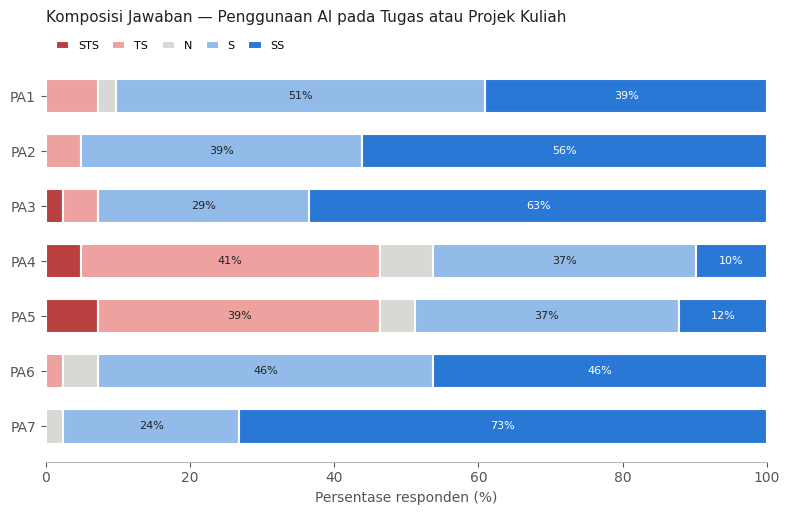

,Kode Butir,Rata-rata,SD,Skewness,Kurtosis,% Setuju (S+SS),% Tidak setuju (STS+TS)
0,PA1,4.22,0.822,-1.289,1.916,90.2,7.3
1,PA2,4.46,0.745,-1.776,3.959,95.1,4.9
2,PA3,4.46,0.925,-2.282,5.515,92.7,7.3
3,PA4,3.05,1.182,0.092,-1.364,46.3,46.3
4,PA5,3.07,1.253,0.016,-1.392,48.8,46.3
5,PA6,4.37,0.698,-1.113,1.852,92.7,2.4
6,PA7,4.71,0.512,-1.520,1.502,97.6,0.0



=== Dimensi 2: Aspek Psikologis Penggunaan AI ===


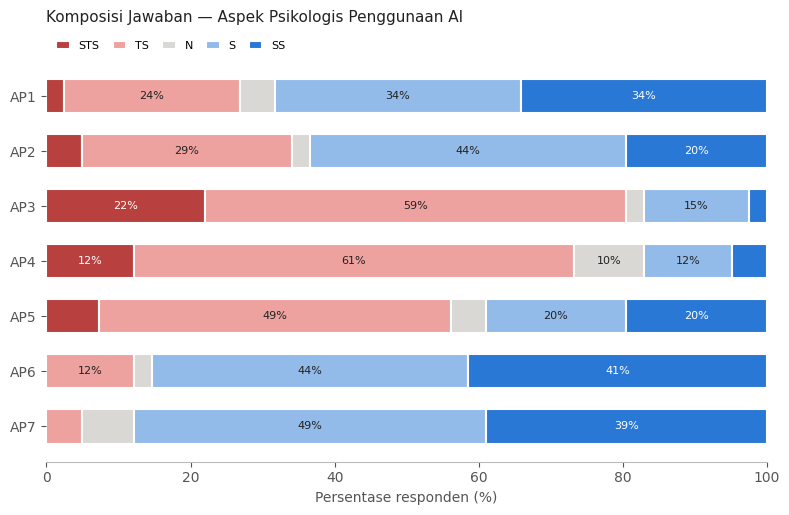

,Kode Butir,Rata-rata,SD,Skewness,Kurtosis,% Setuju (S+SS),% Tidak setuju (STS+TS)
0,AP1,3.73,1.245,-0.602,-1.036,68.3,26.8
1,AP2,3.44,1.246,-0.425,-1.171,63.4,34.1
2,AP3,2.17,1.022,1.116,0.715,17.1,80.5
3,AP4,2.37,1.019,1.129,0.819,17.1,73.2
4,AP5,2.95,1.341,0.420,-1.347,39.0,56.1
5,AP6,4.15,0.963,-1.188,0.703,85.4,12.2
6,AP7,4.22,0.791,-1.058,1.300,87.8,4.9



=== Dimensi 3: Kebiasaan Penggunaan Teknologi Digital ===


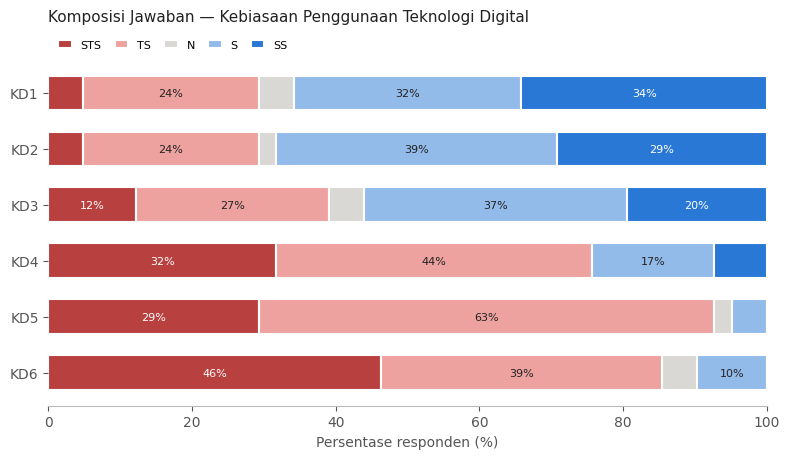

,Kode Butir,Rata-rata,SD,Skewness,Kurtosis,% Setuju (S+SS),% Tidak setuju (STS+TS)
0,KD1,3.66,1.315,-0.571,-1.091,65.9,29.3
1,KD2,3.63,1.280,-0.616,-0.967,68.3,29.3
2,KD3,3.24,1.374,-0.282,-1.333,56.1,39.0
3,KD4,2.24,1.280,0.945,-0.310,24.4,75.6
4,KD5,1.83,0.704,1.158,2.921,4.9,92.7
5,KD6,1.78,0.936,1.235,0.875,9.8,85.4



=== Dimensi 4: Prokrastinasi Akademik ===


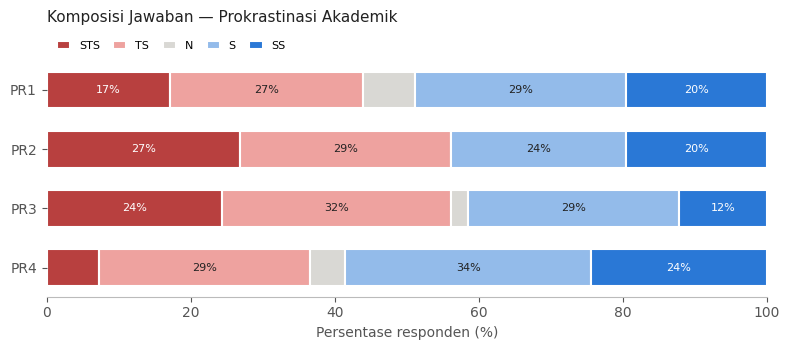

,Kode Butir,Rata-rata,SD,Skewness,Kurtosis,% Setuju (S+SS),% Tidak setuju (STS+TS)
0,PR1,3.07,1.439,-0.081,-1.455,48.8,43.9
1,PR2,2.80,1.553,0.216,-1.600,43.9,56.1
2,PR3,2.73,1.432,0.231,-1.464,41.5,56.1
3,PR4,3.39,1.339,-0.311,-1.326,58.5,36.6



=== Dimensi 5: Respon Emosional ===


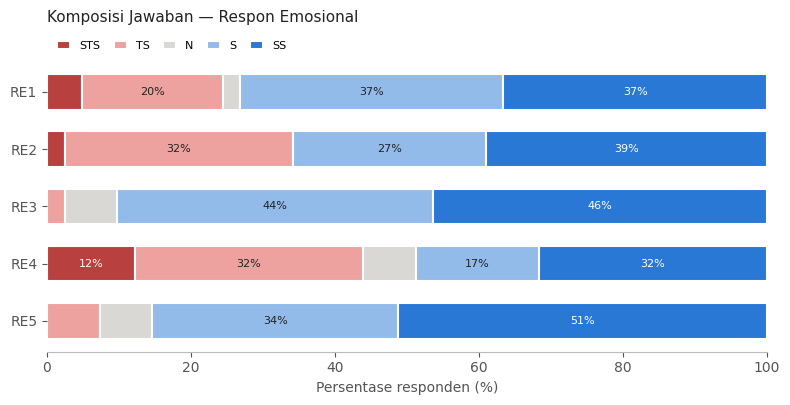

,Kode Butir,Rata-rata,SD,Skewness,Kurtosis,% Setuju (S+SS),% Tidak setuju (STS+TS)
0,RE1,3.80,1.269,-0.848,-0.556,73.2,24.4
1,RE2,3.68,1.350,-0.474,-1.451,65.9,34.1
2,RE3,4.34,0.728,-1.045,1.261,90.2,2.4
3,RE4,3.24,1.496,-0.064,-1.594,48.8,43.9
4,RE5,4.29,0.901,-1.277,1.016,85.4,7.3



Statistik skor total per dimensi


,Dimensi,Skor min teoretis,Skor maks teoretis,Rata-rata total,Rata-rata per butir,SD total,Skewness total,Kurtosis total
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,35,28.34,4.05,3.468,-0.374,0.116
1,Aspek Psikologis Penggunaan AI,7,35,23.02,3.29,4.327,0.136,0.984
2,Kebiasaan Penggunaan Teknologi Digital,6,30,16.39,2.73,3.859,0.019,-0.243
3,Prokrastinasi Akademik,4,20,12.00,3.00,4.319,-0.215,-0.729
4,Respon Emosional,5,25,19.37,3.87,3.562,-0.808,0.293


In [10]:
LABEL = ["STS", "TS", "N", "S", "SS"]
WARNA = ["#b8403f", "#eea29f", "#d9d8d4", "#93bbea", "#2a78d6"]   # palet diverging: merah ↔ abu-abu ↔ biru
os.makedirs("grafik", exist_ok=True)

def komposisi(daftar):
    return (num[daftar].apply(lambda s: s.value_counts(normalize=True)).reindex(range(1, 6)).fillna(0).T * 100)

def grafik_komposisi(nama, daftar, simpan):
    data = komposisi(daftar).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(daftar) + 1.4))
    kiri = np.zeros(len(data))
    for j, (lab, w) in enumerate(zip(LABEL, WARNA), 1):
        nilai = data[j].values
        ax.barh(data.index, nilai, left=kiri, color=w, edgecolor="white", linewidth=1.5, height=0.62, label=lab)
        for yi, (v, l) in enumerate(zip(nilai, kiri)):
            if v >= 8:
                ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if j in (1, 5) else "#222222")
        kiri += nilai
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (%)", color="#555555")
    ax.set_title(f"Komposisi Jawaban — {nama}", loc="left", fontsize=11, color="#222222", pad=28)
    ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=8,
              handlelength=1.2, columnspacing=1.2)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#bbbbbb")
    ax.tick_params(colors="#555555")
    fig.tight_layout()
    fig.savefig(simpan, dpi=200, bbox_inches="tight")
    plt.show()

deskriptif_butir = []
deskriptif_dimensi = []
for idx, (nama, daftar) in enumerate(dimensi.items(), 1):
    print(f"\n=== Dimensi {idx}: {nama} ===")
    grafik_komposisi(nama, daftar, f"grafik/dimensi_{idx}.png")

    x = num[daftar]
    d = pd.DataFrame({
        "Dimensi": nama,
        "Kode Butir": daftar,
        "Rata-rata": x.mean().round(2).values,
        "SD": x.std(ddof=1).round(3).values,
        "Skewness": x.skew().round(3).values,
        "Kurtosis": x.kurt().round(3).values,
        "% Setuju (S+SS)": ((x >= 4).mean() * 100).round(1).values,
        "% Tidak setuju (STS+TS)": ((x <= 2).mean() * 100).round(1).values,
    })
    deskriptif_butir.append(d)
    display(d.drop(columns="Dimensi"))

    total = x.sum(axis=1)
    deskriptif_dimensi.append({
        "Dimensi": nama, "Skor min teoretis": len(daftar), "Skor maks teoretis": 5 * len(daftar),
        "Rata-rata total": round(total.mean(), 2), "Rata-rata per butir": round(x.values.mean(), 2),
        "SD total": round(total.std(ddof=1), 3), "Skewness total": round(total.skew(), 3),
        "Kurtosis total": round(total.kurt(), 3),
    })

deskriptif_butir = pd.concat(deskriptif_butir, ignore_index=True)
deskriptif_dimensi = pd.DataFrame(deskriptif_dimensi)
print("\nStatistik skor total per dimensi")
deskriptif_dimensi

## Langkah 10 — Uji Ulang Setelah Butir Tidak Valid Dibuang

Sesuai modul, pengujian dilakukan berulang: butir tidak valid dibuang, lalu Langkah 5–7 dijalankan ulang
untuk melihat perubahan α (Latihan no. 3).

In [11]:
def uji(num_data, dimensi_data):
    n_ = len(num_data)
    t_ = stats.t.ppf(0.975, n_ - 2)
    rt = t_ / np.sqrt((n_ - 2) + t_**2)
    rows = []
    for nama, daftar in dimensi_data.items():
        x = num_data[daftar]
        tot = x.sum(axis=1)
        for kode in daftar:
            r, _ = stats.pearsonr(x[kode], tot)
            rows.append({"Dimensi": nama, "Kode Butir": kode, "r hitung": round(r, 3),
                         "Keterangan": "Valid" if r > rt else "Tidak valid"})
    return pd.DataFrame(rows), rt

dimensi_iter = {k: list(v) for k, v in dimensi.items()}
riwayat = []
putaran = 0
while True:
    putaran += 1
    tv, rt = uji(num, dimensi_iter)
    tidak_valid = tv[tv["Keterangan"] == "Tidak valid"]
    print(f"Putaran {putaran}: {len(tidak_valid)} butir tidak valid -> {list(tidak_valid['Kode Butir'])}")
    if tidak_valid.empty:
        break
    for _, row in tidak_valid.iterrows():
        dimensi_iter[row["Dimensi"]].remove(row["Kode Butir"])
        riwayat.append({"Putaran": putaran, "Dimensi": row["Dimensi"], "Butir dibuang": row["Kode Butir"],
                        "r hitung": row["r hitung"]})

perbandingan = []
for nama in dimensi:
    a0 = cronbach_alpha(num[dimensi[nama]])
    a1 = cronbach_alpha(num[dimensi_iter[nama]])
    perbandingan.append({
        "Dimensi": nama,
        "Butir awal": len(dimensi[nama]), "α awal": round(a0, 3), "Kategori awal": kategori(a0),
        "Butir akhir": len(dimensi_iter[nama]), "α akhir": round(a1, 3), "Kategori akhir": kategori(a1),
    })
tabel_riwayat = pd.DataFrame(riwayat)
tabel_perbandingan = pd.DataFrame(perbandingan)
display(tabel_riwayat)
display(tabel_perbandingan)

Putaran 1: 2 butir tidak valid -> ['PA7', 'KD5']
Putaran 2: 0 butir tidak valid -> []


,Putaran,Dimensi,Butir dibuang,r hitung
0,1,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,0.086
1,1,Kebiasaan Penggunaan Teknologi Digital,KD5,0.292


,Dimensi,Butir awal,α awal,Kategori awal,Butir akhir,α akhir,Kategori akhir
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,0.604,Tidak reliabel,6,0.645,Tidak reliabel
1,Aspek Psikologis Penggunaan AI,7,0.635,Tidak reliabel,7,0.635,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,6,0.534,Tidak reliabel,5,0.546,Tidak reliabel
3,Prokrastinasi Akademik,4,0.738,Reliabel,4,0.738,Reliabel
4,Respon Emosional,5,0.559,Tidak reliabel,5,0.559,Tidak reliabel


### Simulasi tambahan: membuang butir dengan alpha-jika-dihapus tertinggi

Untuk dimensi yang masih tidak reliabel, dicoba membuang satu butir yang paling menaikkan α. Ini hanya untuk melihat
seberapa jauh α dapat diperbaiki; keputusan akhir tetap mempertimbangkan cakupan isi instrumen.

In [12]:
simulasi = []
for nama, daftar in dimensi_iter.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    if a >= 0.70 or len(daftar) <= 2:
        continue
    kandidat = {k: cronbach_alpha(x.drop(columns=k)) for k in daftar}
    k_max = max(kandidat, key=kandidat.get)
    simulasi.append({"Dimensi": nama, "α saat ini": round(a, 3), "Butir yang dicoba dibuang": k_max,
                     "α setelah dibuang": round(kandidat[k_max], 3), "Kategori": kategori(kandidat[k_max])})
tabel_simulasi = pd.DataFrame(simulasi)
tabel_simulasi

,Dimensi,α saat ini,Butir yang dicoba dibuang,α setelah dibuang,Kategori
0,Penggunaan AI pada Tugas atau Projek Kuliah,0.645,PA3,0.697,Tidak reliabel
1,Aspek Psikologis Penggunaan AI,0.635,AP6,0.640,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,0.546,KD3,0.547,Tidak reliabel
3,Respon Emosional,0.559,RE4,0.703,Reliabel


## Langkah 11 — Menyimpan Hasil Pengujian

In [13]:
NAMA_OUTPUT = "hasil_uji_validitas_reliabilitas_3TI_B.xlsx"
with pd.ExcelWriter(NAMA_OUTPUT) as w:
    tabel_butir.to_excel(w, sheet_name="Daftar Butir", index=False)
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    deskriptif_butir.to_excel(w, sheet_name="Deskriptif Butir", index=False)
    deskriptif_dimensi.to_excel(w, sheet_name="Deskriptif Dimensi", index=False)
    tabel_riwayat.to_excel(w, sheet_name="Uji Ulang - Riwayat", index=False)
    tabel_perbandingan.to_excel(w, sheet_name="Uji Ulang - Alpha", index=False)
    tabel_simulasi.to_excel(w, sheet_name="Simulasi", index=False)
    num.assign(Kelas=KELAS).to_excel(w, sheet_name="Data Numerik", index=False)
print("Hasil disimpan ke", NAMA_OUTPUT)
print("Grafik disimpan di folder grafik/:", sorted(os.listdir("grafik")))

if DI_COLAB:
    files.download(NAMA_OUTPUT)

Hasil disimpan ke hasil_uji_validitas_reliabilitas_3TI_B.xlsx
Grafik disimpan di folder grafik/: ['dimensi_1.png', 'dimensi_2.png', 'dimensi_3.png', 'dimensi_4.png', 'dimensi_5.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ringkasan Akhir

In [14]:
print(f"n = {n}, r tabel = {r_tabel:.3f}, jumlah butir = {num.shape[1]}, jumlah dimensi = {len(dimensi)}")
print(f"Butir valid   : {(tabel_validitas['Keterangan']=='Valid').sum()}")
print(f"Butir tidak valid: {(tabel_validitas['Keterangan']=='Tidak valid').sum()} -> "
      f"{list(tabel_validitas.loc[tabel_validitas['Keterangan']=='Tidak valid','Kode Butir'])}")
print("Dimensi reliabel (α ≥ 0,70):", list(tabel_reliabilitas.loc[tabel_reliabilitas["Cronbach's alpha"] >= 0.70, "Dimensi"]))
print("Dimensi tidak reliabel     :", list(tabel_reliabilitas.loc[tabel_reliabilitas["Cronbach's alpha"] < 0.70, "Dimensi"]))

n = 41, r tabel = 0.308, jumlah butir = 29, jumlah dimensi = 5
Butir valid   : 27
Butir tidak valid: 2 -> ['PA7', 'KD5']
Dimensi reliabel (α ≥ 0,70): ['Prokrastinasi Akademik']
Dimensi tidak reliabel     : ['Penggunaan AI pada Tugas atau Projek Kuliah', 'Aspek Psikologis Penggunaan AI', 'Kebiasaan Penggunaan Teknologi Digital', 'Respon Emosional']
